<a href="https://colab.research.google.com/github/taehi5/Esaa_YB/blob/12%EC%A3%BC%EC%B0%A8-%EA%B3%BC%EC%A0%9C/YB_1120_%EC%97%B0%EC%8A%B5%EB%AC%B8%EC%A0%9C_%ED%9A%8C%EA%B7%802.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1. 규제 선형 회귀 모델/ 회귀 트리**
- 릿지 회귀모델 및 회귀 트리를 이용하여 전복의 나이를 예측해 보세요.

- 전복의 ‘성별’, ‘키’, ‘지름’, ‘높이’, ‘전체무게’, ‘몸통무게’, ‘내장무게’, ‘껍질무게’를 이용해 ‘껍질의 고리수’를 예측한 뒤, **예측된 ‘껍질의 고리수’에 1.5를 더하면 전복의 나이**가 됩니다.

In [1]:
# 기본 모듈 불러오기
import numpy as np
import pandas as pd

import warnings
warnings.filterwarnings(action='ignore')

### 1) 데이터 불러오기 및 데이터 선택

In [2]:
# 데이터 로드
data = pd.read_csv("/content/abalone.csv")

# 성별 M은 Male, F는 Female, I는 Infant 이므로 따로 열 만들기
for label in "MFI":
    data[label] = data["Sex"] == label
data.drop('Sex', axis=1, inplace=True)

# X,y 데이터 선택
y = data.Rings.values
data.drop('Rings', axis=1, inplace=True)

X = data.values.astype(float)

## 2) train/test 분리
: 테스트 셋과 데이터 셋을 7:3 비율로 분리하세요.

In [3]:
# 필요한 모듈 불러오기
from sklearn.model_selection import train_test_split

In [4]:
# train과 test set 분리 (train:test = 7:3 비율로)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,random_state=123)

## 3) 릿지 모델을 이용한 모델링
: 릿지 모델을 이용하여 전복의 나이를 예측해 보고 결과를 평가해 보세요.

 3-1) 릿지모델 생성, 교차검증, 평가에 필요한 모듈을 불러오세요.

In [5]:
# 필요한 모듈 불러오기
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import cross_val_score

3-2) 릿지 모델을 생성하고 훈련하여 MSE와 RMSE를 구하세요. 릿지 모델 생성 시  alpha는 0.3으로 설정합니다. (교차 검증 하지 않습니다.)

In [6]:
# 릿지모델 생성 및 훈련
ridge = Ridge(alpha=0.3, random_state=123)
ridge.fit(X_train, y_train)

# 예측값 구하기 (고리 수 예측)
y_pred_rings = ridge.predict(X_test)

# 구한 예측값을 활용해 최종적으로 전복의 나이 예측
y_pred_age = y_pred_rings + 1.5
y_test_age = y_test + 1.5

# MSE와 RMSE 구하기
mse = mean_squared_error(y_test_age, y_pred_age)
rmse = np.sqrt(mse)

print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")

MSE: 4.7915
RMSE: 2.1890


3-3) 릿지 모델에서 회귀 계수 값을 구해 알 수 있는 점을 작성하시오. (각 컬럼의 정보는 data.colums 참고)

In [7]:
data.columns

Index(['Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight',
       'Viscera weight', 'Shell weight', 'M', 'F', 'I'],
      dtype='object')

In [21]:
ridge_coef = pd.Series(ridge.coef_, index=data.columns, name="회귀 계수")
display(ridge_coef.sort_values(ascending=False))

,회귀 계수
Shell weight,9.571586
Diameter,8.730696
Whole weight,8.400012
Height,8.090955
Length,1.203842
M,0.350188
F,0.267680
I,-0.617868
Viscera weight,-8.894914
Shucked weight,-19.258132


**알 수 있는 점**


다른 피처의 값이 같다고 봤을 때, 회귀 계수가 양수인 피처는 값이 커질수록 예측 고리 수가 늘어나고, 음수인 피처는 예측 고리 수가 줄어든다. 전복의 나이는 고리 수에 1.5를 더해서 구하므로, 예측 나이에도 같은 방향으로 반영된다. 전체 무게, 몸통 무게, 껍질 무게는 서로 관련이 있어서 계수 하나만 보고 그 피처가 전복의 나이에 얼마나 중요한지 판단하기는 어렵다. 릿지는 L2 규제를 사용해 회귀 계수가 너무 커지지 않도록 한다.

3-3) 교차검증을 이용하여 0, 0.1, 1, 10, 100 중  모델 성능이 가장 좋게 나오는 (rmse가 최소가 되는) alpha를 구하세요.

In [9]:
# 주어진 alpha
alphas=[0, 0.1, 1, 10, 100]

In [22]:
for alpha in alphas:
    ridge = Ridge(alpha=alpha)

    #cross_val_score를 이용해 5 폴드의 평균 RMSE를 계산
    neg_mse_scores = cross_val_score(ridge, X, y, scoring="neg_mean_squared_error", cv=5)
    avg_rmse = np.mean(np.sqrt(-1 * neg_mse_scores))
    print(f"alpha {alpha}일 때 5 folds의 평균 RMSE: {avg_rmse:.4f}")

alpha 0일 때 5 folds의 평균 RMSE: 2.2446
alpha 0.1일 때 5 folds의 평균 RMSE: 2.2371
alpha 1일 때 5 folds의 평균 RMSE: 2.2303
alpha 10일 때 5 folds의 평균 RMSE: 2.3373
alpha 100일 때 5 folds의 평균 RMSE: 2.6212


## 4) XGBRegressor을 이용한 모델링
: XGBRegressor 모델을 이용하여 전복의 나이를 예측해 보고 결과를 평가해 보세요.

4-1) XGBRegressor 훈련, 평가에 필요한 모듈을 불러오세요.

In [11]:
# 필요한 모듈 임포트
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error

4-2) XGBregressor 모델을 생성하고 훈련하여 MSE와 RMSE를 구하세요.

In [12]:
# 모델 생성 및 훈련
xgb = XGBRegressor(random_state=123)
xgb.fit(X_train, y_train)

# 예측값 구하기
xgb_pred_rings = xgb.predict(X_test)

# 구한 예측값을 활용해 최종적으로 전복의 나이 예측
xgb_pred_age = xgb_pred_rings + 1.5
y_test_age = y_test + 1.5

# MSE와 RMSE 구하기
xgb_mse = mean_squared_error(y_test_age, xgb_pred_age)
xgb_rmse = np.sqrt(xgb_mse)

print(f"XGBoost MSE: {xgb_mse:.4f}")
print(f"XGBoost RMSE: {xgb_rmse:.4f}")

XGBoost MSE: 5.5804
XGBoost RMSE: 2.3623


4-3) 생성한 모델의 피처 중요도를 시각화해보세요.

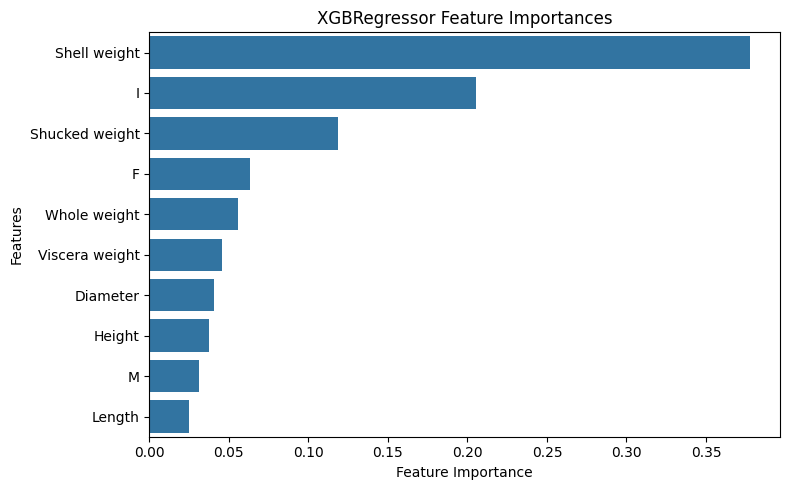

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

importances = pd.Series(xgb.feature_importances_, index=data.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=importances.values, y=importances.index)
plt.title("XGBRegressor Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

# **2. 로지스틱 회귀분석**
load_wine() 함수를 이용하여 와인 데이터를 다항분류하는 로지스틱 회귀모델을 생성하세요.

In [14]:
# 필요한 모듈 불러오기
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

## 1) 데이터 불러오기 및 변수 선택

In [15]:
wine = load_wine()

wine_x = wine.data # x변수
wine_y = wine.target # y변수

## 2) train/test 셋 분리

In [16]:
x_train, x_test, y_train, y_test = train_test_split(wine_x, wine_y, test_size=0.3, random_state=123)

x_train.shape
y_train.shape

(124,)

## 3) 로지스틱 회귀모델을 이용한 모델링

3-1) 로지스틱 회귀모델을 생성하여 훈련하세요.

In [17]:
# 다항분류 로지스틱 회귀모델 생성 및 훈련
log_reg = LogisticRegression(max_iter=5000, random_state=123)
log_reg.fit(x_train, y_train)

LogisticRegression(max_iter=5000, random_state=123)

3-2) 회귀 모델의 기울기와 절편을 구하세요.

In [23]:
#기울기
log_reg.coef_

array([[ 5.40119857e-01,  5.55141609e-01,  6.20476859e-01,
        -2.58233732e-01, -1.45090139e-04,  2.55690914e-01,
         7.52039277e-01,  8.78394493e-02,  1.63790241e-01,
         1.96653394e-01,  1.22113689e-02,  5.19222294e-01,
         8.77112451e-03],
       [-6.96442843e-01, -9.22500438e-01, -7.03121269e-01,
         1.51118933e-01, -4.31236620e-02,  3.12399569e-01,
         1.59485268e-01,  1.17931800e-02,  3.72214630e-01,
        -9.37234424e-01,  2.86879368e-01,  1.35291197e-01,
        -7.77953721e-03],
       [ 1.56322986e-01,  3.67358828e-01,  8.26444092e-02,
         1.07114799e-01,  4.32687521e-02, -5.68090483e-01,
        -9.11524545e-01, -9.96326293e-02, -5.36004871e-01,
         7.40581030e-01, -2.99090737e-01, -6.54513491e-01,
        -9.91587312e-04]])

In [24]:
#절편
log_reg.intercept_

array([-15.57767711,  22.74821606,  -7.17053895])

3-3) 모델의 정확도를 구하세요.

In [20]:
# 모델의 예측값 구하기
y_pred_wine = log_reg.predict(x_test)

# 모델의 정확도 구하기
accuracy = metrics.accuracy_score(y_test, y_pred_wine)
print(f"테스트 세트 정확도: {accuracy:.4f}")

테스트 세트 정확도: 0.9630
